# Forecasting-based anomaly detection: performance and computing cost

This notebook compares two forecasting approaches:

- **Naive forecast:** predicts that the next reading equals the previous reading.
- **Ridge regression:** predicts the next reading from a regularized linear combination of lagged readings.

The authors’ **saved LSTM predictions** provide a detection-performance reference. We will not run or retrain the LSTM, so we will not estimate its forecasting cost.

Our question is: **Does Ridge improve anomaly detection enough to justify its additional computing expense compared with a naive forecast?**

## Shared detection procedure

Each set of forecasts will be processed using `detection.py`. The module contains the detection procedure used by the authors of this dataset. It calculates and smooths prediction errors, selects dynamic thresholds, and buffers and prunes candidate alerts.

Detection settings remain fixed across forecasting methods, while numerical alert thresholds are calculated separately from each method’s prediction errors

## Measurements and cost estimates

For naive and Ridge, we will measure:

- Forecast accuracy using MAE and RMSE.
- Events detected, missed events, false alerts, and event precision, recall, and F1.
- Forecast-generation time, detection-processing time, and combined time.
- Peak memory use, with Ridge training costs reported separately.

The saved LSTM forecasts will be evaluated for forecast accuracy and detection performance. Loading those forecasts will not be counted as LSTM inference time.

Computing expense will be estimated under an explicitly stated ground-based deployment scenario. Cost conclusions will compare naive and Ridge, not their forecasting cost against the LSTM.

## Evaluation plan

P-1 will be our initial case study. Ridge settings will be selected using chronological splits within the supplied training data. P-1’s test data has previously been inspected, which limits its independence as an assessment.

After fixing the comparison procedure, we will aim to apply it to additional channels. Results will describe the forecasters paired with this shared detection procedure.

## Naive one-step-ahead forecast

The naive forecast predicts that the current reading equals the previous
observed reading:

$$
\hat{y}_{t|t-1} = y_{t-1}.
$$

We evaluate it on the same time steps as the saved LSTM predictions,
beginning at index 250 since the authors LSTM model uses 250 previous readings to make its first prediction.

This represents sequential forecasting: once a reading has been observed, it is available for predicting the next one. The forecast never uses the reading it is currently trying to predict.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

repo_dir = Path.cwd().parent
data_dir = repo_dir / "data" / "data"

channel = "P-1"

train_data = np.load(data_dir / "train" / f"{channel}.npy")
test_data = np.load(data_dir / "test" / f"{channel}.npy")

print("Training shape:", train_data.shape)
print("Test shape:", test_data.shape)

Training shape: (2872, 25)
Test shape: (8505, 25)


## Forecast accuracy on matching test readings

We compare the naive forecasts and the authors’ saved LSTM forecasts
against the same number of readings

- **MAE:** the average absolute difference between a forecast and the
  observed reading.
- **RMSE:** the square root of the average squared error. Squaring gives
  larger errors more influence than they have in MAE.

Lower values indicate more accurate forecasts. Both metrics are expressed in scaled telemetry units, not the sensor’s original physical units.

These metrics assess forecasting accuracy, not anomaly detection performance. A model can forecast ordinary behavior accurately while also following anomalous behavior closely, so smaller forecast errors do not necessarily lead to better anomaly alerts.

In [2]:
# Load the saved LSTM forecasts for alignment and later comparison
run_dir = data_dir / "2018-05-19_15.00.10"
lstm_predictions = np.load(run_dir / "y_hat" / f"{channel}.npy")

history_length = 250
n_predictions = 10

# Original test positions associated with the saved LSTM forecasts
evaluation_indices = np.arange(history_length, history_length + len(lstm_predictions))

# Actual readings we will evaluate
actual_readings = test_data[evaluation_indices, 0]

# For each evaluated position t, predict using the observed reading at t - 1
naive_predictions = test_data[evaluation_indices - 1, 0].copy()

assert len(naive_predictions) == len(lstm_predictions)

print("Evaluated readings:", len(actual_readings))
print("First test index:", evaluation_indices[0])
print("Last test index:", evaluation_indices[-1])

pd.DataFrame({
    "test_index": evaluation_indices,
    "actual": actual_readings,
    "naive_forecast": naive_predictions,
    "saved_LSTM_forecast": lstm_predictions}).head()

Evaluated readings: 8245
First test index: 250
Last test index: 8494


,test_index,actual,naive_forecast,saved_LSTM_forecast
0,250,-0.540196,-0.658785,-0.454548
1,251,-0.556930,-0.540196,-0.348632
2,252,-0.227355,-0.556930,-0.082707
3,253,-0.220808,-0.227355,0.251563
4,254,0.417243,-0.220808,0.264749


In [3]:
# Collect accuracy measurements for each forecasting approach
forecast_results = []

# Both prediction arrays correspond to the same evaluation_indices
forecasts = {"Naive"     : naive_predictions,
             "Saved LSTM": lstm_predictions}

for name, predictions in forecasts.items():

    # Calculate one signed forecast error for each evaluated reading
    errors = actual_readings - predictions

    # MAE 
    mae = np.mean(np.abs(errors))

    # RMSE 
    rmse = np.sqrt(np.mean(errors**2))

    forecast_results.append({
        "model": name,
        "MAE"  : mae,
        "RMSE" : rmse})

forecast_accuracy = pd.DataFrame(forecast_results).set_index("model")
forecast_accuracy

,MAE,RMSE
model,,
Naive,0.112885,0.206081
Saved LSTM,0.170085,0.216681


These values for MAE and RMSE summarize errors across **all 8,245 aligned test readings**

The naive forecast has lower MAE (0.112885 versus 0.170085) and RMSE (0.206081 versus 0.216680) than the saved LSTM forecasts. It therefore achieves better overall forecasting accuracy across all test readings for which the authors supplied LSTM forecasts

### This next part passes the naive forecasts through the reproduced detection.py module to generate anomaly alerts

The standard detection procedure is as follows: It calculates absolute prediction errors, smooths them, selects dynamic thresholds, and buffers and prunes candidate alerts.

I retain the settings used for the P-1 LSTM reference. The `history_length=250` setting specifies where our prediction array begins in the test sequence but the naive method itself needs only one previous reading.

The output intervals use original test-data indices, with inclusive endpoints. They are model generated alerts, not yet an assessment of whether those alerts match known labeled anomalies

In [4]:
import sys

# Make detection.py in the repository root available to this notebook
if str(repo_dir) not in sys.path:
    sys.path.insert(0, str(repo_dir))

from detection import detect_anomalies

# Define detection settings for all forecasters (based on the params.log file)
detection_settings = {
    "history_length": 250,
    "n_predictions": 10,
    "target_column": 0,
    "batch_size": 70,
    "window_size": 30,
    "smoothing_perc": 0.05,
    "error_buffer": 100,
    "p": 0.13,
    "initial_adjustment": True,
    "initial_ignore": 500}

# Process the naive forecasts using corrected pruning indexing
# note that ** unpackes the dict into the named arguments
naive_detection = detect_anomalies(test_data=test_data, predictions=naive_predictions, 
                                   **detection_settings)

# Confirm that the detector evaluates our intended time steps
assert np.array_equal(naive_detection["prediction_indices"],evaluation_indices)

print("Evaluated readings:", len(naive_detection["raw_errors"]))
print("Detected alert intervals:", naive_detection["detected_intervals"])
print("Number of separate alerts:", len(naive_detection["detected_intervals"]))

Evaluated readings: 8245
Detected alert intervals: [(2121, 2349)]
Number of separate alerts: 1


`detection.py` groups consecutive retained positions together and starts a new interval wherever there is a gap, confirming that indices 2121–2349 form one uninterrupted alert.

### Comparison of the naive alerts with the expert labled anomlay intervals

For these alerts, the P-1 datachannel belongs to the SMAP sattelite, and P denotes power related telemetry readings. Without more specifics from the authors we are unable to say definitvely what the spacecraft malfunction could be. We just know an interval that's marked for investigation.

The dataset provides expert labeled intervals identifying known anomaly events. We compare our detected alert intervals with those labels using `evaluate_event_detection()` from `detection.py`.

- **True positive (TP):** a labeled event overlaps at least one alert.
- **False positive (FP):** an alert overlaps no labeled event.
- **False negative (FN):** a labeled event overlaps no alert.

Any overlap counts as detecting an event. The alert does not need to cover the entire labeled interval

In [5]:
import ast
from detection import evaluate_event_detection

# Locate the labels within the cloned repository
label_paths = list(repo_dir.rglob("labeled_anomalies.csv"))

labels = pd.read_csv(label_paths[0])

# Select the annotation for our channel
channel_labels = labels.loc[labels["chan_id"] == channel]


# Convert the CSV's text representation into a Python list of intervals
labeled_intervals = ast.literal_eval(channel_labels["anomaly_sequences"].iloc[0])

# Compare detected intervals with the labeled events
naive_evaluation = evaluate_event_detection(detected_intervals=naive_detection["detected_intervals"],
labeled_intervals=labeled_intervals)

print("Channel:", channel)
print("Known anomaly intervals:", labeled_intervals)
print("Detected alert intervals using naive forecast:", naive_detection["detected_intervals"])

pd.DataFrame([{
    "method": "Naive forecast based detection",
    "TP": naive_evaluation["TP"],
    "FP": naive_evaluation["FP"],
    "FN": naive_evaluation["FN"]}]).set_index("method")

Channel: P-1
Known anomaly intervals: [[2149, 2349], [4536, 4844], [3539, 3779]]
Detected alert intervals using naive forecast: [(2121, 2349)]


,TP,FP,FN
method,,,
Naive forecast based detection,1,0,2


The detection procedure produced one alert at test indices **2121–2349**

It overlaps the labeled anomaly at **2149–2349**, so one event was detected
(**TP = 1**)

The other two labeled events were missed (**FN = 2**). The single alert
overlaps a known event, so there were no false alert intervals (**FP = 0**)

For this channel, the approach detected **one of three known events** while producing no false alerts. This demonstrates conservative alerting, but limited event coverage under the fixed detection settings

### Ridge regression

This forecasting method learns a weighted combination of input features to predict a numerical value. The inputs are previous telemetry redings and the target is the next reading.

$$
\hat y_t = b + w_1y_{t-1} + w_2y_{t-2} + \cdots + w_py_{t-p}.
$$

The history length $p$ determines how many previous readings are supplied. Unlike the naive forecast, which simply copies the previous value, Ridge learns its coefficients, the weights  $w_1,\ldots,w_p$, and intercept $b$ from training data

Ridge adds a penalty on large coefficients when fitting because they can make predictions overly sensitive to small changes in the inputs. The regularization parameter $\alpha$ controls this penalty

I will select the history length and $\alpha$ using chronological validation within the supplied training sequence. **Test readings are then inputs to that fixed equation not data used to update its weights**

Since at each test time step Ridge receives only previously observed readings to forecast the current reading, using past test readings as inputs is consistent with our one-step-ahead forecasting setup. The current target and future readings are not inputs

Finally, `detection.py` will process Ridge's prediction errors using the same settings as the naive comparison. We will assess whether any gain in detection performance justifies the additional computation



### Construct forecasting inputs and targets

The input columns contain the three readings immediately before time step t. The target is the observed reading at t. The current target is kept separate from the inputs to prevent the regression from receiving the answer it is meant to predict.

The first three rows are excluded because they lack the required history.

In [6]:
# Use only the telemetry column from the supplied training array.
training_readings = pd.Series(train_data[:, 0], name="telemetry")

# shift(j) places the reading from j steps earlier on the current row.
ridge_example = pd.DataFrame({
    "previous_1": training_readings.shift(1),
    "previous_2": training_readings.shift(2),
    "previous_3": training_readings.shift(3),
    "target": training_readings}).dropna()

# Display the first five complete prediction tasks. The left most column is the row number
ridge_example.head()

,previous_1,previous_2,previous_3,target
3,-0.554993,-0.688857,-0.523155,-0.531114
4,-0.531114,-0.554993,-0.688857,-0.589001
5,-0.589001,-0.531114,-0.554993,-0.555716
6,-0.555716,-0.589001,-0.531114,-0.721418
7,-0.721418,-0.555716,-0.589001,-0.756150


### Process of selecting Ridge's settings

1. Compare a small set of history lengths, such as 3, 10, and 30 readings

2. Compare several values of $\alpha$. Ex 0.01, 0.1, 1, 10, and 100

3. Use **expanding window chronological validation within the training sequence**: fit on an earlier portion, validate on the next portion, then advance

4. Compare candidiates on the same validation time steps so longer histories do not change which targets are evaluated. Meaning, later splits expand the fitting portion while preserving time order

All candidates will use targets beginning at training index 30 which is the earliest portion with sufficient history for every candidate

Validation forecasts may use earlier observed readings from the validation blocks as inputs. Ridge's coefficients remain fixed throughout that block but the current target and future readings are never forecasting inputs



### Selection and final evaluation

I will select the history length and $\alpha$ with the lowest pooled validation RMSE across the chronological splits. If scores tie exactly, we will refer fewer lags, then stronger regularization

After selection, I will refit Ridge using all eligible targets in the supplied training sequence

Then, forecast the same test positions used by the naive and saved LSTM comparisons and apply the unchanged `detection.py` settings

Again, test readings, test anomaly labels, and test detection results will not be used to select Ridge's settings. Selecting by forecast RMSE does not guarantee the best anomaly detection. The final comparison evaluates whether the resulting errors produce useful alerts.

### Chronological split boundaries

I will use five expanding window splits. The first uses approximately 50 percent of eligible training targets for fitting and the following 10 percent for validation. Each subsequent split expands the fitting portion and validates on the next block

Within every split, all fitting targets precede all validation targets. A validation block may become part of the fitting data in a later split, representing the availability of more observations over time.

These boundaries are shared by every history length and $\alpha$ candidate.
No supplied test readings are included.

In [7]:
# Candidate settings, fixed before fitting or examining validation results.
# No real reason for choosing these specifically
history_lengths = [3, 10, 30]
alpha_values = [0.01, 0.1, 1.0, 10.0, 100.0]

# Every candidate uses the same target positions, beginning at index 30
max_history = max(history_lengths)
training_target_indices = np.arange(max_history, len(training_readings))
n_targets = len(training_target_indices)

# Boundaries at approximately 50%, 60%, ..., 100% of eligible targets
# Integer conversion rounds down to whole positions
boundaries = (np.linspace(0.5, 1.0, 6) * n_targets).astype(int)

cv_splits = []
split_rows = []

for split_number in range(5):
    fit_stop = boundaries[split_number]
    validation_stop = boundaries[split_number + 1]

    # Positions within the common target array, for later use in fitting.
    fit_positions = np.arange(fit_stop)
    validation_positions = np.arange(fit_stop, validation_stop)

    cv_splits.append((fit_positions, validation_positions))

    # Translate those positions back to original training time step indices.
    fit_times = training_target_indices[fit_positions]
    validation_times = training_target_indices[validation_positions]

    assert fit_times[-1] < validation_times[0]

    split_rows.append({
        "split": split_number + 1,
        "first fitting target": fit_times[0],
        "last fitting target": fit_times[-1],
        "fitting targets": len(fit_times),
        "first validation target": validation_times[0],
        "last validation target": validation_times[-1],
        "validation targets": len(validation_times)})

split_summary = pd.DataFrame(split_rows)
split_summary

,split,first fitting target,last fitting target,fitting targets,first validation target,last validation target,validation targets
0,1,30,1450,1421,1451,1734,284
1,2,30,1734,1705,1735,2018,284
2,3,30,2018,1989,2019,2302,284
3,4,30,2302,2273,2303,2586,284
4,5,30,2586,2557,2587,2871,285


The table confirms five expanding window splits within the supplied training sequence. Each split fits on earlier targets and validates on the following block. Validation blocks contain 284 or 285 targets because the available readings do not divide evenly.

All history length and regularization candidates will use these same target positions. Targets begin at index 30 so every candidate has sufficient history. The supplied test sequence remains outside this parameter selection procedure.

### Lagged inputs for each candidate history length

For each target reading y, the inputs are the previous p readings

I construct separate input tables for $p=3$, $p=10$, and $p=30$

Every table uses the same target time steps beginning at 30. The current target is stored
separately and is never included as a forecasting input.

In [8]:
# Store one input table for each candidate history length.
lagged_inputs = {}

for history in history_lengths:

    # Each column contains readings from a specified number of steps ago
    features = pd.DataFrame({
        f"previous_{lag}": training_readings.shift(lag)
        for lag in range(1, history + 1)})

    # Select the common target indices so all candidates use identical rows
    lagged_inputs[history] = features.loc[training_target_indices].copy()

# Store the observed readings we want Ridge to predict
ridge_targets = training_readings.loc[ training_target_indices].copy()

# Verify that every input table aligns with the targets and has no missing values
for history, features in lagged_inputs.items():
    assert features.index.equals(ridge_targets.index)
    assert not features.isna().any().any()

    print(
        f"History {history}: "
        f"{features.shape[0]} prediction tasks, "
        f"{features.shape[1]} input columns")

# Display the three-lag inputs beside their targets for inspection.
display(lagged_inputs[3].join(ridge_targets.rename("target")).head())

History 3: 2842 prediction tasks, 3 input columns
History 10: 2842 prediction tasks, 10 input columns
History 30: 2842 prediction tasks, 30 input columns


,previous_1,previous_2,previous_3,target
30,-0.500000,-0.546310,-0.544139,-0.546310
31,-0.546310,-0.500000,-0.546310,-0.956585
32,-0.956585,-0.546310,-0.500000,-0.468162
33,-0.468162,-0.956585,-0.546310,-0.429812
34,-0.429812,-0.468162,-0.956585,0.111433


### Interpretation of the lagged-input tables

Each history length provides **2,842 prediction tasks**, using the same training targets at indices 30–2871. The input tables contain 3, 10, or 30 columns, depending on how many previous readings are supplied.

The displayed example shows the three-reading history. At index **30**, the inputs are readings from indices **29, 28, and 27**, and the target is the observed reading at index **30**. Moving to row 31 advances this arrangement by one time step. 


### Fit and compare Ridge candidates

For each history length and regularization strength, I fit a separate Ridge model on each split's fitting portion. Ridge learns its coefficients by minimizing:

$$
\sum_{t\in\mathrm{fit}}
\left(y_t-b-\sum_{j=1}^{p}w_jy_{t-j}\right)^2
+\alpha\sum_{j=1}^{p}w_j^2.
$$

I then predict the following validation block without updating the coefficients. Its lagged inputs contain only readings observed before each prediction target.

I pool squared errors across the five validation blocks and calculate one validation RMSE per candidate. Lower RMSE indicates better validation forecast accuracy

In [9]:
from sklearn.linear_model import Ridge

ridge_validation_rows = []

for history in history_lengths:
    X = lagged_inputs[history]

    for alpha in alpha_values:
        squared_error_sum = 0.0
        n_validated = 0

        for fit_positions, validation_positions in cv_splits:

            # These are row POSITIONS in our time ordered tables
            X_fit = X.iloc[fit_positions]
            y_fit = ridge_targets.iloc[fit_positions]

            X_validation = X.iloc[validation_positions]
            y_validation = ridge_targets.iloc[validation_positions]

            # Learn new coefficients using only this split's fitting data
            candidate = Ridge(alpha=alpha, fit_intercept=True)
            candidate.fit(X_fit, y_fit)

            # Predict the next block using the fixed fitted coefficients
            validation_predictions = candidate.predict(X_validation)

            # Accumulate errors so every validation target has equal weight
            errors = y_validation.to_numpy() - validation_predictions
            squared_error_sum += np.sum(errors**2)
            n_validated += len(errors)

        pooled_rmse = np.sqrt(squared_error_sum / n_validated)

        ridge_validation_rows.append({
            "history": history,
            "alpha": alpha,
            "validation targets": n_validated,
            "validation_RMSE": pooled_rmse})

# Rank by RMSE
ridge_validation_results = (pd.DataFrame(ridge_validation_rows).sort_values(
    ["validation_RMSE", "history", "alpha"],
    ascending=[True, True, False]).reset_index(drop=True))

ridge_validation_results

,history,alpha,validation targets,validation_RMSE
0,30,1.00,1421,0.195295
1,30,0.10,1421,0.195364
2,30,0.01,1421,0.195373
3,30,10.00,1421,0.195729
4,10,0.01,1421,0.196350
5,10,0.10,1421,0.196351
6,10,1.00,1421,0.196372
7,10,10.00,1421,0.197341
8,3,0.01,1421,0.198384
9,3,0.10,1421,0.198390


Upon sorting the results, its shown that among the 15 candidate combinations **30 previous readings and $\alpha$ = 1** achieved the lowest pooled validation RMSE: **0.196295**

I therefore select these settings according to the predefined rule.

Every candidate was evaluated on the same **1421 validation targets** across five chronological splits, making the errors directly comparable. Longer histories overall performed better, although the differences among the leading candidates are small. 

The next step is to refit the selected Ridge configuration on the supplied training data and generate forecasts for the agreed test time steps. To do so, select the first row of the ranked validation results: **30 lags and $\alpha$ = 1**. Ridge is then fitted using all 2,842 eligible training targets, including the portions previously used for validation.

I construct test inputs from the preceding 30 observed readings and forecast the same 8,245 time steps used by the naive and saved LSTM comparisons. The fitted coefficients remain fixed during test prediction.

Again, each test input contains only readings preceding its target. The current target and future readings are excluded.

In [10]:
# Retrieve the selected settings from our ranked validation results
best_settings = ridge_validation_results.iloc[0]

selected_history = int(best_settings["history"])
selected_alpha = float(best_settings["alpha"])

# Fit the selected configuration on all common training targets
# No test readings or anomaly labels enter this fit
ridge_model = Ridge(
alpha=selected_alpha,
fit_intercept=True)

ridge_model.fit(
lagged_inputs[selected_history],
ridge_targets)

# Construct test features with the same names and ordering as training
test_readings = pd.Series(test_data[:, 0], name="telemetry")

test_features = pd.DataFrame({
    f"previous_{lag}": test_readings.shift(lag)
    for lag in range(1, selected_history + 1)})

# Select exactly the test positions used in the other comparisons
X_test_ridge = test_features.loc[evaluation_indices].copy()

assert not X_test_ridge.isna().any().any()
assert list(X_test_ridge.columns) == list(lagged_inputs[selected_history].columns)
assert np.array_equal(X_test_ridge.index.to_numpy(),evaluation_indices)

# Generate one-step-ahead forecasts with the fitted coefficients.
ridge_predictions = ridge_model.predict(X_test_ridge)

assert ridge_predictions.shape == actual_readings.shape

print("Selected history length:", selected_history)
print("Selected alpha:", selected_alpha)
print("Training targets used:", len(ridge_targets))
print("Test forecasts generated:", len(ridge_predictions))

# Inspect alignment, rather than judging accuracy from only five examples.
pd.DataFrame({
    "test_index": evaluation_indices,
    "actual": actual_readings,
    "naive_forecast": naive_predictions,
    "ridge_forecast": ridge_predictions,
    "saved_LSTM_forecast": lstm_predictions}).head()

Selected history length: 30
Selected alpha: 1.0
Training targets used: 2842
Test forecasts generated: 8245


,test_index,actual,naive_forecast,ridge_forecast,saved_LSTM_forecast
0,250,-0.540196,-0.658785,-0.615020,-0.454548
1,251,-0.556930,-0.540196,-0.431147,-0.348632
2,252,-0.227355,-0.556930,-0.430758,-0.082707
3,253,-0.220808,-0.227355,-0.169925,0.251563
4,254,0.417243,-0.220808,-0.161568,0.264749


### Compare forecast accuracy across all three methods

Now calculate MAE and RMSE across the same 8,245 test targets for the naive forecast, fitted Ridge model, and saved LSTM forecasts.

Lower values indicate better forecasting accuracy. This comparison does not select new Ridge settings, those were fixed using training only validation. Anomaly detection performance will be assessed separately

In [11]:
# All arrays predict the same readings in actual_readings.
forecasts = {
    "Naive": naive_predictions,
    "Ridge": ridge_predictions,
    "Saved LSTM": lstm_predictions}

forecast_results = []

for name, predictions in forecasts.items():
    assert predictions.shape == actual_readings.shape

    # Calculate forecast errors over the entire aligned test sequence
    errors = actual_readings - predictions

    forecast_results.append({
        "method": name,
        "evaluated readings": len(errors),
        "MAE": np.mean(np.abs(errors)),
        "RMSE": np.sqrt(np.mean(errors**2))})

forecast_accuracy = pd.DataFrame(forecast_results).set_index("method")
forecast_accuracy

,evaluated readings,MAE,RMSE
method,,,
Naive,8245,0.112885,0.206081
Ridge,8245,0.130886,0.193368
Saved LSTM,8245,0.170085,0.216681


## Results

When all three methods are evaluated on the same **8245 test readings**, the **naive forecast has the lowest MAE** (0.112885) while **Ridge has the lowest RMSE** (0.193368), indicating better performance under a metric that gives larger errors more weight.

Compared with the naive forecast, Ridge reduces RMSE by approximately **$6.2\%$**, but increases MAE by approximately **$15.9\%$**. Neither method is therefore best under both measures. The saved LSTM forecasts have higher MAE and RMSE than both alternatives on these readings.

Next apply the same detection procedure to Ridge’s errors to determine which known events it identifies and how many false alerts it produces by passing the Ridge forecast through `detection.py` with the same settings as the naieve comparison. Once again, The module calculates the prediction errors and turns them into alert intervals.

I compare those intervals with the expert labels. A labeled event overlapping an alert counts as detected (TP); an alert overlapping no labeled event is a false positive (FP); a labeled event with no overlapping alert is missed (FN).

In [12]:
# Generate alerts from Ridge forecasts using the existing shared settings.
ridge_detection = detect_anomalies(
test_data=test_data,
predictions=ridge_predictions,
**detection_settings)

# Verify that detection uses the agreed test positions
assert np.array_equal(ridge_detection["prediction_indices"],evaluation_indices)

# Evaluate alerts against the same labels used for the naive forecasts
ridge_evaluation = evaluate_event_detection(
detected_intervals=ridge_detection["detected_intervals"],
 labeled_intervals=labeled_intervals)

print("Known anomaly intervals:", sorted(labeled_intervals))
print("Detected alert intervals:", ridge_detection["detected_intervals"])
print("Number of alert intervals:", len(ridge_detection["detected_intervals"]))

# Compare event counts for naive and Ridge forecast-based detection.
event_comparison = pd.DataFrame([
    {
        "method": name,
        "TP": evaluation["TP"],
        "FP": evaluation["FP"],
        "FN": evaluation["FN"]
    }
    for name, evaluation in [
        ("Naive forecast-based detection", naive_evaluation),
        ("Ridge forecast-based detection", ridge_evaluation)
    ]]).set_index("method")

event_comparison

Known anomaly intervals: [[2149, 2349], [3539, 3779], [4536, 4844]]
Detected alert intervals: [(4520, 4729)]
Number of alert intervals: 1


,TP,FP,FN
method,,,
Naive forecast-based detection,1,0,2
Ridge forecast-based detection,1,0,2


## The event counts are identical, but the methods detect different events!

| Known anomaly interval | Naive-based detection | Ridge-based detection |
|---|---|---|
| 2149–2349 | Detected | Missed |
| 3539–3779 | Missed | Missed |
| 4536–4844 | Missed | Detected |

Ridge’s lower forecast RMSE therefore did not translate into more detected events under the fixed detection procedure. Aggregate counts alone also conceal which events each approach finds.


### Saved LSTM detection reference

Process now the authors’ saved LSTM forecasts using the same detection settings and evaluated time steps as the naive and Ridge forecasts.

This provides a detection performance reference. I do not run the LSTM model, so this comparison does not measure its forecasting time or memory use

In [13]:
# Generate alerts from the saved LSTM forecasts.
lstm_detection = detect_anomalies(
test_data=test_data,
predictions=lstm_predictions,
**detection_settings)

assert np.array_equal(lstm_detection["prediction_indices"],evaluation_indices)

# Evaluate using the same expert labeled events
lstm_evaluation = evaluate_event_detection(
detected_intervals=lstm_detection["detected_intervals"],
labeled_intervals=labeled_intervals)

# Retain these collections for subsequent tables and plots
detections = {
    "Naive": naive_detection,
    "Ridge": ridge_detection,
    "Saved LSTM": lstm_detection}

evaluations = {
    "Naive": naive_evaluation,
    "Ridge": ridge_evaluation,
    "Saved LSTM": lstm_evaluation}

event_comparison = pd.DataFrame([
    {
        "forecast source": name,
        "alert intervals": len(detections[name]["detected_intervals"]),
        "TP": result["TP"],
        "FP": result["FP"],
        "FN": result["FN"],
        "precision": result["precision"],
        "recall": result["recall"],
        "F1": result["f1"]
    }
    for name, result in evaluations.items()]).set_index("forecast source")

print("Saved LSTM alert intervals:", lstm_detection["detected_intervals"])

display(event_comparison)

Saved LSTM alert intervals: [(2130, 2349), (3190, 3329), (3540, 3679), (4520, 4589)]


,alert intervals,TP,FP,FN,precision,recall,F1
forecast source,,,,,,,
Naive,1,1,0,2,1.00,0.333333,0.500000
Ridge,1,1,0,2,1.00,0.333333,0.500000
Saved LSTM,4,3,1,0,0.75,1.000000,0.857143


### Comparing event-detection performance

Using the same detection procedure, the naive and Ridge forecasts each detected **one of three known events**, with no false alert intervals. They detected different events, despite having identical summary metrics.

The saved LSTM forecasts produced **four alert intervals**: three overlapped known events and one did not.

The LSTM reference therefore achieved greater event coverage, at the expense of one false alert. Its poorer overall forecasting accuracy did not prevent it from producing more useful anomaly signals under this detection procedure.

The figure shows whether each labeled event overlaps at least one alert. An event is counted as detected even if the alert covers only part of it.

This complements the summary metrics: naive and Ridge have identical event counts but detect different events. False alerts are not shown in this figure; they remain reported in the comparison table.

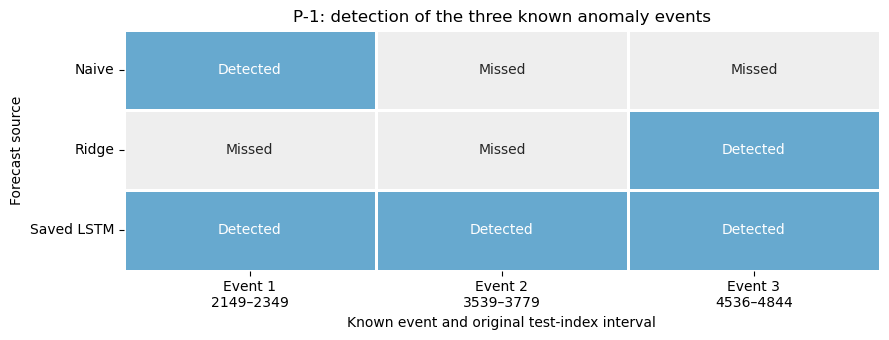

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# The CSV's intervals are not necessarily in chronological order.
# Reorder both the event labels and their detection indicators consistently
event_order = sorted(range(len(labeled_intervals)), key=lambda i: labeled_intervals[i][0])

event_names = [
    f"Event {number}\n{labeled_intervals[i][0]}–{labeled_intervals[i][1]}"
    for number, i in enumerate(event_order, start=1)]

# The evaluator records whether each known event was detected
event_coverage = pd.DataFrame(
    {
        name: np.asarray(result["detected_event_mask"])[event_order]
        for name, result in evaluations.items()
    },
    index=event_names).T

# Use explicit words so the figure does not rely on color alone
annotations = np.where(event_coverage.to_numpy(), "Detected", "Missed")

fig, ax = plt.subplots(figsize=(9, 3.5))

sns.heatmap(
    event_coverage.astype(int),
    annot=annotations,
    fmt="",
    cmap=["#eeeeee", "#67a9cf"],
    vmin=0,
    vmax=1,
    cbar=False,
    linewidths=2,
    linecolor="white",
    ax=ax)

ax.set_title("P-1: detection of the three known anomaly events")
ax.set_xlabel("Known event and original test-index interval")
ax.set_ylabel("Forecast source")
ax.tick_params(axis="y", labelrotation=0)

plt.tight_layout()
plt.show()

### Computational benchmark scope

Now that comparisons are complete, its time to measure runtime and memory for naive and Ridge, then use those measurements to estimate computing expense under explicit deployment and pricing assumptions

I will benchmark naive and Ridge forecasting on the same computer and the same 8,245 test targets.

Forecast generation time will include construction of the required inputs and generation of predictions. Detection time will measure a separate call to `detect_anomalies()`, including error calculation, smoothing, threshold selection, buffering, pruning, and diagnostic output creation.

Data loading, imports, plotting, and evaluation against anomaly labels will be excluded. Ridge fitting and parameter selection will be reported separately from repeated forecast generation.

I will repeat timings and report their median and variability. Memory will be measured separately so memory monitoring overhead does not affect the runtime benchmark.

These are batch-processing measurements, not real-time alert latency. Saved LSTM predictions provide a performance reference only; no LSTM forecasting-cost comparison will be claimed.

### Prepare repeatable forecasting operations

The naive operation retrieves the preceding observed reading for each target. The Ridge operation constructs the required lagged inputs and applies the already fitted regression.

Both operations forecast the same 8,245 test readings. Ridge fitting is excluded here because it is a separate training cost.

Before measuring runtime, verify that these functions reproduce the forecasts already evaluated. These correctness checks are performed outside the timed operations.

In [18]:
# simple diagnostic check
def generate_naive_forecasts(test_data, target_indices):
    """Predict each target using the preceding observed telemetry reading."""

    return test_data[target_indices - 1, 0].copy()


def generate_ridge_forecasts(
    test_data,
    target_indices,
    fitted_ridge,
    history):
    
    """Construct past-reading inputs and predict using fixed Ridge weights."""

    readings = pd.Series(test_data[:, 0], name="telemetry")

    # Rebuild the lagged inputs on every call so their construction cost
    # is included when we benchmark this operation
    features = pd.DataFrame({
        f"previous_{lag}": readings.shift(lag)
        for lag in range(1, history + 1)})

    # Keep only the agreed evaluation targets.
    inputs = features.loc[target_indices]

    # Prediction does not update the fitted coefficients.
    return fitted_ridge.predict(inputs)


# Check that the reusable operations reproduce the existing forecasts
naive_check = generate_naive_forecasts(
test_data,
evaluation_indices)

ridge_check = generate_ridge_forecasts(
test_data,
evaluation_indices,
ridge_model,
selected_history)

assert np.allclose(naive_check, naive_predictions)
assert np.allclose(ridge_check, ridge_predictions)

### Runtime measurement procedure

I am interested in asking "how long does it take a computer to process the same 8245 readings using each forecasting method?"

There are two main steps:
- **Forecast generation:** construct inputs and generate predictions.
- **Detection only:** process existing predictions through `detection.py`.

I want to time each separately, then time both together. This will determine if most of the computation comes from forecasting or from the detection procedure

For reliable measurments:
1. Warm-up: run once before measuring, so initial setup has less influence
2. Seven repetitions: repeat because runtime fluctuates with other computer activity
3. Median: report the middle measurement rather than relying on one run
4. Interquartile range: show the spread of the middle half of measurements
5. One numerical library thread: keep that computing setting consistent between methods

For very fast operations, I will time many calls together and divide by the number of calls to estimate the time for one execution

In [21]:
import timeit
from threadpoolctl import threadpool_limits

# Each callable performs forecasting from the same loaded test data.
forecast_operations = {
    "Naive": lambda: generate_naive_forecasts(
        test_data, evaluation_indices
    ),
    "Ridge": lambda: generate_ridge_forecasts(
        test_data, evaluation_indices, ridge_model, selected_history)}

# Existing predictions let us measure detection without forecasting.
existing_predictions = {
    "Naive": naive_predictions,
    "Ridge": ridge_predictions}


def run_complete_pipeline(forecast_operation):
    """Generate forecasts, then calculate errors and produce alert intervals."""

    predictions = forecast_operation()

    return detect_anomalies(
        test_data=test_data,
        predictions=predictions,
        **detection_settings)


runtime_rows = []

# Apply the same numerical thread limit to every timed operation
with threadpool_limits(limits=1):

    for name, forecast_operation in forecast_operations.items():
        predictions = existing_predictions[name]

        operations = {
            "Forecast generation": forecast_operation,
            "Detection only": lambda: detect_anomalies(
                test_data=test_data,
                predictions=predictions,
                **detection_settings
            ),
            "Complete pipeline": lambda: run_complete_pipeline(
                forecast_operation)}

        for stage, operation in operations.items():
            # Warm up outside the recorded measurements.
            operation()

            timer = timeit.Timer(operation)

            # Choose enough calls for a measurement lasting at least ~0.2 s.
            calls_per_repeat, _ = timer.autorange()

            # Each result is the elapsed time for one batch of calls.
            elapsed = np.asarray(
                timer.repeat(repeat=7, number=calls_per_repeat)
            )

            # Convert batch durations into milliseconds per operation.
            milliseconds = elapsed / calls_per_repeat * 1000

            runtime_rows.append({
                "forecast source": name,
                "stage": stage,
                "calls per repeat": calls_per_repeat,
                "median ms": np.median(milliseconds),
                "25th percentile ms": np.percentile(milliseconds, 25),
                "75th percentile ms": np.percentile(milliseconds, 75)
            })

runtime_results = pd.DataFrame(runtime_rows)

display(runtime_results) # this is the second run. first was overwritten

,forecast source,stage,calls per repeat,median ms,25th percentile ms,75th percentile ms
0,Naive,Forecast generation,10000,0.029379,0.029371,0.029825
1,Naive,Detection only,2,136.462072,135.482212,136.775434
2,Naive,Complete pipeline,2,141.439527,138.870609,145.541526
3,Ridge,Forecast generation,50,4.370324,4.240436,4.564816
4,Ridge,Detection only,2,114.116466,112.339192,117.553475
5,Ridge,Complete pipeline,2,118.816739,118.053517,120.083204


### The main finding is that detection processing dominates runtime, rather than forecast generation.

First run:

| Stage | Naive | Ridge |
|---|---:|---:|
| Forecast generation | 0.030 ms | 4.030 ms |
| Detection only | 146.85 ms | 110.04 ms |
| Complete pipeline | 136.92 ms | 118.58 ms |

Second Run:

| Stage | Naive | Ridge |
|---|---:|---:|
| Forecast generation | 0.029 ms | 4.370 ms |
| Detection only | 136.46 ms | 114.12 ms |
| Complete pipeline | 141.44 ms | 118.82 ms |


All values are **median runtimes for processing 8,245 test targets**, not times per reading. Forecast generation includes input preparation. Detection includes error calculation, smoothing, threshold selection, buffering, and pruning.

Ridge forecasting was slower, but its complete pipeline was faster in both runs because detection processing took less time for its forecasts. Detection workload can differ even with identical settings.

The complete pipeline was timed independently, so its median need not equal the sum of the separately measured stage medians. Runtime also varies with computer activity and measurement order. Timings varied between runs and were collected in a fixed order. These results describe our implementation on this computer.

These findings describe our implementation on P-1 and this computer. They exclude Ridge training and parameter selection and do not measure LSTM inference cost.

### Runtime comparison

We use the second benchmark run as the reference measurement. Each runtime covers all 8,245 evaluated P-1 targets.

The three panels use different vertical scales so forecasting time remains visible alongside the much longer detection time. Error bars show the 25th–75th percentiles of the repeated measurements, not confidence intervals.

In [3]:
import matplotlib.pyplot as plt

import pandas as pd

# Preserve the recorded second run rather than relying on an overwritten variable.
runtime_reference = pd.DataFrame([
    ["Naive", "Forecast generation", 0.029379, 0.029371, 0.029825],
    ["Naive", "Detection only", 136.462072, 135.482212, 136.775434],
    ["Naive", "Complete pipeline", 141.439527, 138.870609, 145.541526],
    ["Ridge", "Forecast generation", 4.370324, 4.240436, 4.564816],
    ["Ridge", "Detection only", 114.116466, 112.339192, 117.553475],
    ["Ridge", "Complete pipeline", 118.816739, 118.053517, 120.083204]
], columns=["method", "stage", "median_ms", "q25_ms", "q75_ms"])

runtime_reference["channel"] = "P-1"
runtime_reference["evaluated_targets"] = 8245
runtime_reference["benchmark_run"] = 2

# Save figures and tables inside the project repository
results_dir = repo_dir / "results" / "forecasting_cost_comparison"
results_dir.mkdir(parents=True, exist_ok=True)

colors = {"Naive": "#4477AA", "Ridge": "#EE7733"}
stages = ["Forecast generation", "Detection only", "Complete pipeline"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, stage in zip(axes, stages):
    subset = (
        runtime_reference.loc[runtime_reference["stage"] == stage]
        .set_index("method")
        .loc[["Naive", "Ridge"]])

    medians = subset["median_ms"].to_numpy()

    # Asymmetric error bars span the recorded interquartile range.
    error_bars = np.vstack([
        medians - subset["q25_ms"].to_numpy(),
        subset["q75_ms"].to_numpy() - medians])

    bars = ax.bar(
        subset.index,
        medians,
        color=[colors[name] for name in subset.index],
        yerr=error_bars,
        capsize=5)

    ax.bar_label(bars, labels=[f"{value:.3f}" for value in medians], padding=5)
    ax.set_title(stage)
    ax.set_ylabel("Milliseconds per 8,245 targets")
    ax.set_ylim(0, subset["q75_ms"].max() * 1.25)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle("P-1 processing time: second benchmark run")
fig.tight_layout()

fig.savefig(results_dir / "Naive_Ridge_Runtime_Comparison.png", dpi=200, bbox_inches="tight")
plt.show()

NameError: name 'repo_dir' is not defined

### Illustrative ground-computing cost scenario

#### Computing-price reference

The official [AWS Fargate pricing page](https://aws.amazon.com/fargate/pricing/) describes charges for running applications with allocated CPU and memory.

Under **Pricing Examples → Example 1**, AWS lists Linux/x86 rates for US East (N. Virginia): **\$0.000011244** per vCPU-second and **\$0.000001235** per GB-second. The Duration section specifies per-second billing with a one-minute minimum and rounding up to whole seconds.

I use these prices to translate assumed resource allocations and running times into illustrative computing expenses. The source provides pricing but does not establish our application's cloud runtime or memory needs. I have not deployed the pipeline on AWS Fargate.

**Assumptions:**

- Allocate **1 vCPU and 2 GB of memory** to either method.
- Process **1,000 P-1-sized batches per day**, each containing 8,245
  evaluation targets, for **30 days**.
- Run one task per day, processing the batches sequentially and then
  terminating. No parallel speedup is assumed.
- Allow **30 seconds per daily task** for startup and other overhead.
- Examine cloud processing times of **0.5×, 1×, and 2×** the local
  benchmark time.
- Exclude training, parameter selection, storage, networking, logging,
  taxes, and human alert investigation.

We apply AWS’s one-minute minimum and whole-second rounding as billing
rules. The workload is hypothetical. It does not imply that the dataset's time steps represent any particular number of seconds or days.

For each method, $t_{\mathrm{batch}}$ is the measured complete-pipeline runtime converted from milliseconds to **seconds**, and $s$ is the assumed cloud-to-local runtime multiplier:

$$
t_{\mathrm{daily}} =
1000 \times t_{\mathrm{batch}} \times s + 30.
$$

The estimated monthly computing expense is:

$$
C_{\mathrm{month}} =
30 \times \max(60,\lceil t_{\mathrm{daily}}\rceil)
\times
\left(r_{\mathrm{CPU}} + 2r_{\mathrm{memory}}\right).
$$

Here, $r_{\mathrm{CPU}}$ is the price per vCPU-second and $r_{\mathrm{memory}}$ is the price per GB-second. The CPU term assumes 1 vCPU, and the factor 2 represents 2 GB of allocated memory. The outer factor 30 represents the number of daily tasks in the month.

The maximum and ceiling apply AWS’s minimum billed duration and whole-second rounding.

In [24]:
# calculate the estimates

# Published Fargate Linux/x86 example rates, US East (N. Virginia).
cpu_price_per_second = 0.000011244
memory_price_per_gb_second = 0.000001235

allocated_vcpus = 1
allocated_memory_gb = 2

batches_per_day = 1000
days_per_month = 30
startup_seconds_per_day = 30
runtime_multipliers = [0.5, 1.0, 2.0]

# The hourly price alone does not determine cost:
# allocated resources and billed duration both matter.
allocated_price_per_second = (
    allocated_vcpus * cpu_price_per_second
    + allocated_memory_gb * memory_price_per_gb_second)

pipeline_times = (
    runtime_reference.loc[
        runtime_reference["stage"] == "Complete pipeline"].set_index("method")["median_ms"] / 1000)

cost_rows = []

for multiplier in runtime_multipliers:
    for method, batch_seconds in pipeline_times.items():

        processing_seconds = (
            batches_per_day * batch_seconds * multiplier
        )

        # Include assumed overhead and the provider's billing rules
        daily_task_seconds = (
            processing_seconds + startup_seconds_per_day
        )
        billed_seconds_per_day = max(
            60, int(np.ceil(daily_task_seconds))
        )

        monthly_cost = (
            billed_seconds_per_day
            * days_per_month
            * allocated_price_per_second
        )

        cost_rows.append({
            "method": method,
            "runtime multiplier": multiplier,
            "processing seconds per day": processing_seconds,
            "billed seconds per day": billed_seconds_per_day,
            "estimated monthly USD": monthly_cost
        })

cost_estimates = pd.DataFrame(cost_rows)

display(cost_estimates.round(4))

# A continuously provisioned task is billed while running, even when idle.
always_running_monthly_cost = ( days_per_month * 24 * 3600 * allocated_price_per_second)

print(
    "Same allocation running continuously for 30 days:",
    f"${always_running_monthly_cost:.2f}")

,method,runtime multiplier,processing seconds per day,billed seconds per day,estimated monthly USD
0,Naive,0.5,70.7198,101,0.0416
1,Ridge,0.5,59.4084,90,0.0370
2,Naive,1.0,141.4395,172,0.0708
3,Ridge,1.0,118.8167,149,0.0613
4,Naive,2.0,282.8791,313,0.1288
5,Ridge,2.0,237.6335,268,0.1103


Same allocation running continuously for 30 days: $35.55


The table estimates monthly computing expense for each forecasting method
under three assumed cloud runtimes. Processing time covers 1,000 batches per day and billed time adds 30 seconds of overhead and applies AWS’s billing rules. Monthly costs assume 30 daily tasks. T
he **$35.55** figure instead assumes the same resources remain allocated continuously for 30 days.

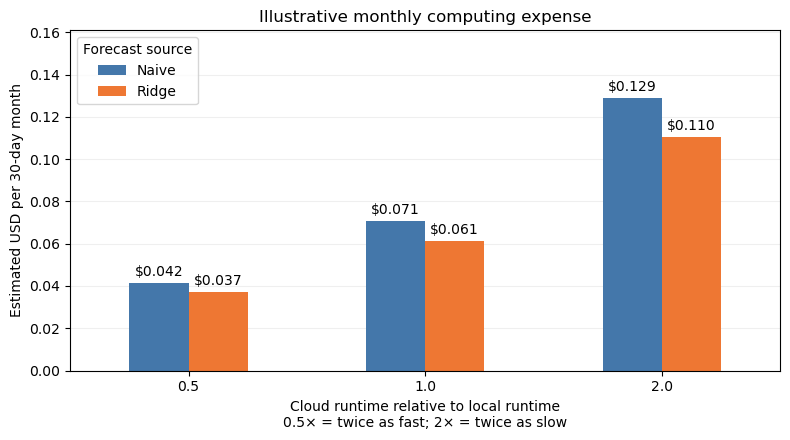

In [27]:
cost_plot = (
    cost_estimates.pivot(
        index="runtime multiplier",
        columns="method",
        values="estimated monthly USD"
    ).reindex(columns=["Naive", "Ridge"]))

ax = cost_plot.plot.bar(
    figsize=(8, 4.5),
    color=[colors["Naive"], colors["Ridge"]],
    rot=0)

for container in ax.containers:
    ax.bar_label(container, fmt="$%.3f", padding=3)

ax.set_title("Illustrative monthly computing expense")
ax.set_xlabel(
    "Cloud runtime relative to local runtime\n"
    "0.5× = twice as fast; 2× = twice as slow")
ax.set_ylabel("Estimated USD per 30-day month")
ax.set_ylim(0, cost_plot.to_numpy().max() * 1.25)
ax.legend(title="Forecast source")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    results_dir / "cost_scenarios.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Preserve the numerical results used in the figures.
runtime_reference.to_csv(
    results_dir / "runtime_second_run.csv", index=False
)
cost_estimates.to_csv(
    results_dir / "computing_cost_scenarios.csv", index=False
)
event_comparison.to_csv(
    results_dir / "event_detection_comparison.csv"
)

### Interpreting the cost-scenario plot

This plot asks: **What would our measured processing times cost under
three assumptions about how quickly a cloud computer runs the same code?**

Each batch contains **8,245 evaluated telemetry readings**. We assume
1,000 batches per day for 30 days. Each pipeline generates forecasts and
uses `detection.py` to turn prediction errors into anomaly alerts.

The blue bars represent the **naive forecast-based pipeline**; the orange
bars represent the **Ridge forecast-based pipeline**.

#### Horizontal axis: assumed cloud runtime

We measured runtime on the computer used to run this notebook, not on AWS. The multiplier converts that local measurement into an assumed cloud processing time:

- **0.5×:** the cloud takes half as long as our computer.
- **1×:** the cloud takes the same time as our computer.
- **2×:** the cloud takes twice as long as our computer.

For example, Ridge’s complete pipeline took approximately **0.119 seconds
per batch locally**. Its assumed cloud processing times are therefore
approximately **0.059, 0.119, and 0.238 seconds per batch**.

These multipliers apply to processing time. The assumed daily startup
overhead remains 30 seconds in every scenario.

#### Vertical axis: estimated monthly computing expense

We convert the assumed running time into dollars using the published
price for **1 vCPU and 2 GB of allocated memory**. The calculation includes
daily startup overhead and AWS’s minimum-duration and rounding rules.

At **1×**, the estimated monthly expenses are:

- **Naive: approximately \$0.071, or 7.1 cents.**
- **Ridge: approximately \$0.061, or 6.1 cents.**

These small expenses assume one short task runs each day and then stops. They do not represent the cost of keeping the resources running continuously.

#### What the comparison means

Ridge has a lower estimate because its complete forecasting-and-detection
pipeline ran faster locally, despite slower forecast generation. The
difference is approximately **one cent per month at 1×**.

The three scenarios show how the estimates change under different runtime
assumptions. They are **not confidence intervals, measured cloud results,
or evidence that the assumed resources are sufficient**. The plot also
does not measure detection quality. That is reported separately.

## Conclusions

Ridge achieved lower forecast RMSE than the naive rule, but higher MAE.

After applying the same detection procedure, each detected **one of P-1’s
three known events**, with no false alert intervals. They detected different events. The saved LSTM forecasts detected **all three events**, with one false alert. Better overall forecasting accuracy therefore did not guarantee better anomaly detection.

Detection processing dominated runtime. Ridge’s complete pipeline ran faster in both benchmark runs, despite slower forecast generation. These measurements describe our implementation on the computer used to run this notebook.

Assuming equal cloud and local processing times, estimated monthly computing expenses were approximately **7.1 cents for naive** and **6.1 cents for Ridge**. This difference does not justify choosing Ridge on financial savings alone. Keeping the assumed resources running
continuously would instead cost approximately **$35.55 per month**: the operating schedule matters more than method choice in this scenario.

This work provides a reusable detection procedure and connects its detection results with measured runtime and explicit computing-cost assumptions. The results are a P-1 case study, not a general ranking.

Actual cloud performance, memory requirements, training costs, LSTM
inference costs, and human alert-review costs were not measured.